# 1장 능동 학습 개요

라벨링 비용, 학습 곡선, 평가 지표를 다룬다. 이 노트북은 책 전체가 쓰는 데이터 분할을 만들어 `data/` 에 저장하고 학습 곡선 아래 면적(ALC)과 라벨 효율 함수를 정의한다.

- 1.1 라벨링 비용과 능동 학습의 동기
- 1.2 능동 학습 시나리오의 분류
- 1.3 실습 데이터셋의 구성
- 1.4 학습 곡선과 라벨 효율
- 1.5 학습 곡선 아래 면적(ALC)과 라벨 효율 지표
- 1.6 이 책의 비교 실험 틀

코드는 1.3~1.5절에 있다. CPU만으로 돌고 NSMC와 KLUE-YNAT를 인터넷에서 내려받는다.

In [1]:
# ── 환경 설정과 상수 ────
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

SEED = 42                       # 데이터 분할 시드
SEEDS = [0, 1, 2, 3, 4]         # 실험 반복 시드
N_POOL, N_VAL, N_TEST = 20000, 2000, 10000
ACCENT, INK, GRAY, GRAY2 = "#E32C24", "#1C1C1A", "#575753", "#8C8A85"
for folder in ("data", "results", "out"):
    os.makedirs(folder, exist_ok=True)

/opt/miniconda3/envs/lecture/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1.3 실습 데이터셋의 구성

NSMC는 네이버 영화 리뷰 감성(긍정·부정) 데이터이고 KLUE-YNAT는 연합뉴스 기사 제목 7개 주제 분류 데이터다. 빈 문장과 중복 문장을 지우고 층화 추출로 풀 20,000, 검증 2,000, 시험셋을 만든다. YNAT 공식 test는 라벨이 공개되지 않아 공식 validation을 시험셋으로 쓴다.

In [2]:
# ── NSMC 내려받기와 정제 ────
NSMC_URL = "https://raw.githubusercontent.com/e9t/nsmc/master/ratings_{}.txt"

def read_nsmc(split):
    df = pd.read_csv(NSMC_URL.format(split), sep="\t", quoting=3)
    return df.rename(columns={"document": "text"})[["text", "label"]]

def clean(df):
    df = df.dropna().assign(text=lambda d: d.text.str.strip())
    return df[df.text.str.len() > 0].drop_duplicates("text").reset_index(drop=True)

nsmc_train, nsmc_test = clean(read_nsmc("train")), clean(read_nsmc("test"))
print("NSMC train", len(nsmc_train), "test", len(nsmc_test))

NSMC train 146182 test 49157


In [3]:
# ── YNAT 내려받기와 정제 ────
ynat = load_dataset("klue/klue", "ynat")
YNAT_NAMES = ynat["train"].features["label"].names

def to_frame(split):
    return clean(ynat[split].to_pandas().rename(columns={"title": "text"})[["text", "label"]])

ynat_train, ynat_valid = to_frame("train"), to_frame("validation")
print("YNAT train", len(ynat_train), "validation", len(ynat_valid))
print(dict(enumerate(YNAT_NAMES)))

YNAT train 45678 validation 9107
{0: 'IT과학', 1: '경제', 2: '사회', 3: '생활문화', 4: '세계', 5: '스포츠', 6: '정치'}


In [4]:
# ── 층화 분할과 저장 ────
def split_and_save(name, train, test):
    test = test[~test.text.isin(train.text)]          # 학습 쪽과 겹치는 시험 문장을 뺀다
    pool, rest = train_test_split(train, train_size=N_POOL, stratify=train.label, random_state=SEED)
    val, _ = train_test_split(rest, train_size=N_VAL, stratify=rest.label, random_state=SEED)
    for split, df in zip(("pool", "val", "test"), (pool, val, test)):
        df.reset_index(drop=True).to_csv(f"data/{name}_{split}.csv", index=False)

nsmc_test = nsmc_test[~nsmc_test.text.isin(nsmc_train.text)]
nsmc_test_sub, _ = train_test_split(nsmc_test, train_size=N_TEST, stratify=nsmc_test.label, random_state=SEED)
split_and_save("nsmc", nsmc_train, nsmc_test_sub)
split_and_save("ynat", ynat_train, ynat_valid)
with open("data/ynat_labels.json", "w") as f:
    json.dump(YNAT_NAMES, f, ensure_ascii=False)

In [5]:
# ── 데이터 통계 ────
SPLITS = {name: {s: pd.read_csv(f"data/{name}_{s}.csv") for s in ("pool", "val", "test")}
          for name in ("nsmc", "ynat")}

table_1_1 = pd.DataFrame([dict(데이터=name, 분할=s, 크기=len(df), 클래스=df.label.nunique(),
                               평균길이=round(df.text.str.len().mean(), 1))
                          for name, sp in SPLITS.items() for s, df in sp.items()])
print(table_1_1.to_string(index=False))

for name, sp in SPLITS.items():
    print(f"\n{name} 클래스 비율")
    print(pd.concat({s: df.label.value_counts(normalize=True).sort_index() for s, df in sp.items()}, axis=1).round(3))

 데이터   분할    크기  클래스  평균길이
nsmc pool 20000    2  36.3
nsmc  val  2000    2  35.9
nsmc test 10000    2  36.7
ynat pool 20000    7  27.4
ynat  val  2000    7  27.2
ynat test  9107    7  27.1

nsmc 클래스 비율
        pool    val   test
label                     
0      0.502  0.501  0.497
1      0.498  0.498  0.503

ynat 클래스 비율
        pool    val   test
label                     
0      0.115  0.114  0.061
1      0.134  0.134  0.148
2      0.112  0.112  0.406
3      0.126  0.126  0.150
4      0.182  0.182  0.092
5      0.170  0.170  0.063
6      0.162  0.162  0.079


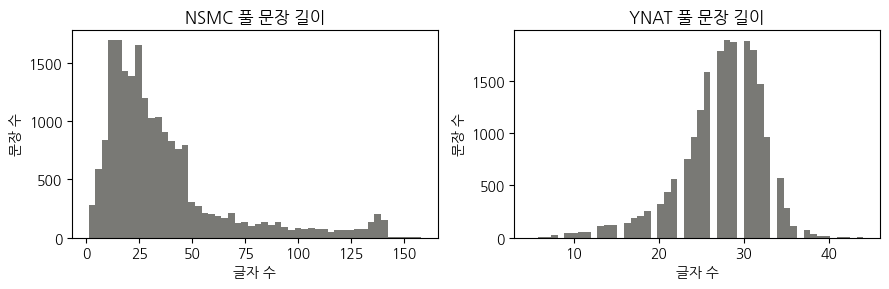

In [6]:
# ── 문장 길이 분포 ────
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for ax, (name, sp) in zip(axes, SPLITS.items()):
    ax.hist(sp["pool"].text.str.len(), bins=50, color=GRAY, alpha=0.8)
    ax.set(title=f"{name.upper()} 풀 문장 길이", xlabel="글자 수", ylabel="문장 수")
fig.tight_layout()
fig.savefig("out/ch01_length_hist.png", dpi=200)

## 1.4 학습 곡선과 라벨 효율

라벨을 무작위로 100개부터 풀 전체 20,000개까지 늘리며 TF-IDF와 로지스틱 회귀를 학습한다. 곡선이 얼마나 빨리 포화하는지가 능동 학습이 줄일 수 있는 라벨링 비용의 크기를 정한다.

In [7]:
# ── 전체 라벨 학습 곡선 ────
def load_xy(name):
    pool, test = SPLITS[name]["pool"], SPLITS[name]["test"]
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2,
                          max_features=50000, sublinear_tf=True)
    return vec.fit_transform(pool.text), pool.label.values, vec.transform(test.text), test.label.values

SIZES = [100, 200, 500, 1000, 2000, 5000, 10000, 20000]
rows = []
for name in ("nsmc", "ynat"):
    X, y, X_te, y_te = load_xy(name)
    for seed in SEEDS:
        order = np.random.default_rng(seed).permutation(len(y))
        for n in SIZES:
            idx = order[:n]
            y_hat = LogisticRegression(C=10.0, max_iter=1000, random_state=seed).fit(X[idx], y[idx]).predict(X_te)
            rows.append(dict(data=name, seed=seed, n_labeled=n, acc=accuracy_score(y_te, y_hat),
                             f1=f1_score(y_te, y_hat, average="macro")))
full = pd.DataFrame(rows)
full.to_csv("results/ch01_full_curve.csv", index=False)
print(full.groupby(["data", "n_labeled"])[["acc", "f1"]].agg(["mean", "std"]).round(4))

                   acc              f1        
                  mean     std    mean     std
data n_labeled                                
nsmc 100        0.5614  0.0368  0.4878  0.0881
     200        0.6434  0.0336  0.6201  0.0528
     500        0.7179  0.0112  0.7144  0.0124
     1000       0.7541  0.0062  0.7533  0.0065
     2000       0.7814  0.0059  0.7813  0.0060
     5000       0.8063  0.0029  0.8063  0.0029
     10000      0.8209  0.0032  0.8209  0.0032
     20000      0.8315  0.0000  0.8315  0.0000
ynat 100        0.1835  0.0594  0.1789  0.0810
     200        0.2594  0.0383  0.3025  0.0325
     500        0.4232  0.0284  0.4640  0.0240
     1000       0.5390  0.0234  0.5662  0.0186
     2000       0.6311  0.0239  0.6476  0.0182
     5000       0.7194  0.0093  0.7250  0.0093
     10000      0.7609  0.0044  0.7620  0.0048
     20000      0.7903  0.0000  0.7893  0.0000


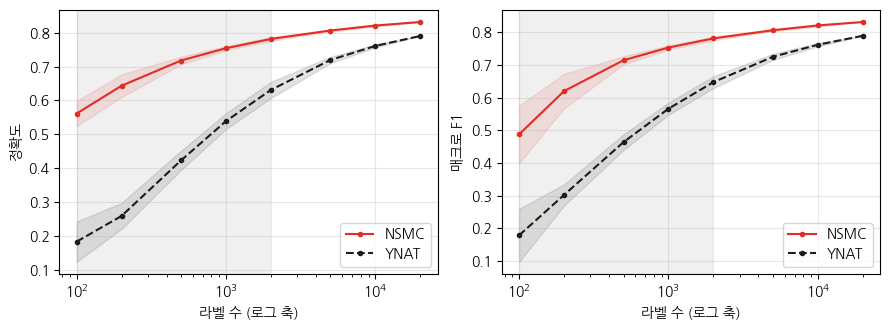

In [8]:
# ── 전체 라벨 학습 곡선 그림 ────
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, metric, ylabel in zip(axes, ("acc", "f1"), ("정확도", "매크로 F1")):
    for (name, g), c, ls in zip(full.groupby("data"), (ACCENT, INK), ("-", "--")):
        s = g.groupby("n_labeled")[metric].agg(["mean", "std"])
        ax.plot(s.index, s["mean"], color=c, ls=ls, marker="o", ms=3, label=name.upper())
        ax.fill_between(s.index, s["mean"] - s["std"], s["mean"] + s["std"], color=c, alpha=0.12)
    ax.axvspan(100, 2000, color=GRAY2, alpha=0.12)
    ax.set(xscale="log", xlabel="라벨 수 (로그 축)", ylabel=ylabel)
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
fig.savefig("out/ch01_full_learning_curve.png", dpi=200)

## 1.5 학습 곡선 아래 면적(ALC)과 라벨 효율 지표

ALC는 라벨 수 축을 [n₀, B]에서 [0, 1]로 정규화하고 성능 곡선을 사다리꼴로 적분한 값이다. 라벨 효율은 Random이 예산 B에서 낸 성능에 처음 도달한 라벨 수 n*로 B를 나눈 값이다.

In [9]:
# ── ALC와 라벨 효율 함수 ────
def alc(n, m, budget):
    # 라벨 수를 [n0, budget] → [0, 1]로 정규화한 사다리꼴 적분. n0은 첫 측정점이다
    keep = n <= budget
    u, m = (n[keep] - n[0]) / (budget - n[0]), m[keep]
    return np.sum(np.diff(u) * (m[1:] + m[:-1]) / 2)

def label_efficiency(n, m, m_target, budget):
    hit = n[m >= m_target]
    return budget / hit[0] if len(hit) else np.nan

In [10]:
# ── 지표 계산 예시: 무작위 학습 곡선의 ALC ────
mean_curve = full.groupby(["data", "n_labeled"])[["acc", "f1"]].mean()
for name in ("nsmc", "ynat"):
    c = mean_curve.loc[name]
    print(f"{name}: ALC(acc, 100~2000) = {alc(c.index.values, c.acc.values, 2000):.4f}, "
          f"ALC(F1, 100~2000) = {alc(c.index.values, c.f1.values, 2000):.4f}")

nsmc: ALC(acc, 100~2000) = 0.7369, ALC(F1, 100~2000) = 0.7315
ynat: ALC(acc, 100~2000) = 0.5001, ALC(F1, 100~2000) = 0.5281


ALC random = 0.7616, ALC fast = 0.7830
목표 성능 0.7946, 빠른 곡선 도달 라벨 수 1000, 라벨 효율 = 2.00


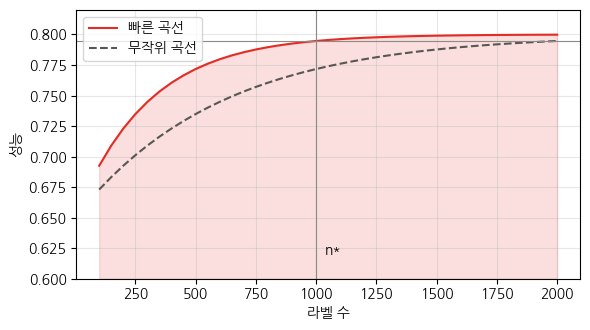

In [11]:
# ── 지표 계산 예시: 가상의 두 곡선 ────
n = np.arange(100, 2001, 50)
m_random = 0.80 - 0.15 * np.exp(-n / 600)     # 가상의 무작위 곡선
m_fast = 0.80 - 0.15 * np.exp(-n / 300)       # 가상의 더 빠른 곡선
target = m_random[-1]
n_star = n[m_fast >= target][0]
print(f"ALC random = {alc(n, m_random, 2000):.4f}, ALC fast = {alc(n, m_fast, 2000):.4f}")
print(f"목표 성능 {target:.4f}, 빠른 곡선 도달 라벨 수 {n_star}, 라벨 효율 = {label_efficiency(n, m_fast, target, 2000):.2f}")

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.fill_between(n, 0.6, m_fast, color=ACCENT, alpha=0.15)
ax.plot(n, m_fast, color=ACCENT, label="빠른 곡선")
ax.plot(n, m_random, color=GRAY, ls="--", label="무작위 곡선")
ax.axhline(target, color=GRAY2, lw=0.8)
ax.axvline(n_star, color=GRAY2, lw=0.8)
ax.annotate("n*", (n_star, 0.62), xytext=(6, 0), textcoords="offset points")
ax.set(ylim=(0.6, 0.82), xlabel="라벨 수", ylabel="성능")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig("out/ch01_alc_example.png", dpi=200)